# 3.6 · Barings QGARP, reconstructed

> **Needs:** the research cache with analysts' estimates (source `estimates`) and the rule set `gems-2026-11` (`eqr load-rules`, part of every build), and the database.
>
> **Produces:** registered runs of the family `barings_qgarp`, with the hold-out opened.

Barings' **QGARP** strategy - quality and growth at a reasonable price - scores every stock on about 130 factors and
combines them into composites (value, growth, quality, momentum and earnings-estimate revisions), and finally into
one QGARP score. This notebook reconstructs those scores from the strategy's rules on our own point-in-time data, and
backtests a portfolio of the highest-scoring stocks.

**The strategy's rules:**

| Step | Rule |
|---|---|
| Factors | Worldscope fundamentals (yields, margins, returns on capital and their five-year stability, accruals, growth), prices (1-12 month returns, trend t-statistic, volatility), I/B/E/S estimates (forward yields, expected growth, revisions) |
| Cleaning | values outside each factor's limits set to missing, not clipped (a lower and an upper limit per factor) |
| Value | percentile rank of the mean rank of six yields (financials: earnings and book yield only) |
| Growth | ranks of cash-flow, EPS, shareholder-yield and sustainable growth, computed separately within banks & insurers and within all other stocks |
| Quality | an *alpha* half (profitability, cash-flow quality, accruals) and a *defensive* half (stable profits, low EPS forecast dispersion, low debt), computed within banks, other financials and the rest |
| Momentum | z-scores of the 1, 3, 6, 9 and 12-month returns, clipped at ±3, averaged and standardised again |
| **QGARP** | `-(0.2 alpha + 0.1 defensive + 0.3 growth + 0.3 value + 0.1 revisions)` of each input's percentile rank, a missing rank set to 50.5 (the median); then its own percentile rank, 1 = best. As originally coded, the revisions z-score is ranked the wrong way round - the *worst* revisions score best; this notebook corrects it (below) |

Ranking within groups (banks, other financials, the rest) compares financials, whose accounts differ, only with
each other; and percentile ranks are insensitive to outliers - which is why the strategy can combine factors measured
on very different scales.

**The portfolio** (ours: the strategy defines a score, not a fund): at each month end, buy the top 20 % of the S&P
1500 by QGARP, keep a holding while it stays in the top 30 % (a buffer against turnover), equally weighted, with
costs of 0.10 / 0.25 / 0.50 % per trade for large / mid / small caps. The benchmark is SPTM, the S&P 1500 ETF, with
dividends.

**One correction to the original, by choice.** The original ranks the 1-month revisions z-score ascending, like the
percentile ranks - but a z-score is better when *higher*, so a company whose analysts are cutting their forecasts
scores best on that input. This notebook ranks it the right way round (`FIX_REVISIONS_DIRECTION = True`), decided on
that reasoning before the backtest was run: the screen should reward upgrades, as every other input rewards the good
end. Set it to `False` to reproduce the original exactly.

The QGARP weights are a parameter (`QGARP_WEIGHTS` in the first code cell), Barings' by default. Any composite can
be given a weight - momentum, for example, which QGARP leaves out - but every change is our variant, not Barings'
rule, and the registry counts it as a new trial. The cleaning limits are a parameter too (`RULES`): the rule set
`"gems-2026-11"` holds Barings' limits; `None` cleans nothing, as the runs before November 2026 did.

**The hold-out look (opened 14 November 2026).** The runs end on 11 November 2026, so they include the hold-out from
January 2025 - the months the research had set aside. Every setting was fixed before the look: Barings' weights and
limits, and the revisions direction chosen on 13 November. **What counts, written before the run:** the screen's
active return against SPTM over the hold-out alone, with its t-statistic (the table *In sample and hold-out* below).
A positive active return supports the screen; a negative one with a t-statistic below -1 counts against it. The
look is not a clean one: notebook 3.5 has already shown the same strategy's hold-out on the S&P 500, two-thirds of
this universe by value. And twenty-two months are few - a genuine edge of one or two points a year would itself show
a t-statistic of about 0.5, so the look can refute a large edge, not prove a modest one. The other sections (deciles,
triage) now span 2010-2026, hold-out included.

**Data coverage - read the results with this in mind:**

* **Analysts' estimates are included** (I/B/E/S from LSEG, monthly since 2005): forward earnings, sales and EBIT
  yields, expected growth, EPS forecast dispersion and revisions - 34 of the strategy's 35 estimate factors
  (`sales_revisions_1_mth` needs revenue revision counts, which are not loaded). With them the growth composite can
  be formed and QGARP has all five components.
* **Revision counts exclude delisted companies (survivorship bias).** LSEG returns past revision counts only for
  stocks still listed today (a company since delisted or acquired answers 0 raised and 0 lowered): a third of 2015's
  constituents have none, in QGARP's revisions input (weight 10 %). This biases the backtest, not the screen - today's
  companies are all listed. Their consensus, yields and expected growth are all present, and the section *Revisions
  without survivorship bias* measures revisions from the consensus instead.
* **Every accounting item is included** (since 2026-10-31): depreciation (EBITDA and free-cash-flow yields),
  inventories, financing cash flows (shareholder yield), unusual items and the bank items (capital ratios, loans,
  deposits, loan-loss provisions, non-performing loans). The SEC supplies all of them from its XBRL filings (2009-2011
  on); LSEG, for earlier years and for companies the SEC lacks, has all but the financing details - so before the
  SEC's data, shareholder yield is zero for every stock (as coded, a missing flow counts as zero) and adds nothing.
* **Approximations of Worldscope's line items**: EBITDA is EBIT + depreciation; Worldscope's extraordinary credits and
  charges are one net unusual figure (LSEG's, or the SEC's restructuring and impairment charges less gains on
  disposals) split by sign; risk-weighted assets are tier-1 capital divided by the tier-1 ratio where not reported.
* **Barings' cleaning limits are applied** (since November 2026; rule set `gems-2026-11`, kept in the shared tables
  `research.rule_set` / `research.strategy_rule`, where every strategy's rules live): a lower and an upper limit for
  117 scores, 100 of them factors built here - an earnings yield must lie between -50 % and +50 %, a dividend yield
  between 0 and 20 %, a debt-to-equity ratio between -5 and 5. A value outside its limits is set to missing rather
  than pulled back to the limit: the company is then not ranked on that factor at all, instead of being ranked as the
  cheapest or the most indebted. The 17 factors built here that have no limits (among them the bank ratios, the
  five-year volatilities and market capitalisation) are kept whole. The section *Cleaning* below counts what the
  limits remove.

**Deliberate differences from the original**: statements are used from their publication date (the original uses a
period as soon as it ends, a look-ahead of several weeks); the universe is the S&P 1500 in US dollars, not a global
one; Worldscope's industry classes are mapped from GICS. The full list is in `research/barings_garp.py`.

In [1]:
import pandas as pd
from IPython.display import display

from equity_research.data.cache import ResearchCache
from equity_research.strategies import barings_garp as bg
from equity_research.strategies import rules as strategy_rules
from research_core import charts
from research_core.analytics.performance.metrics import decile_returns, performance
from research_core.analytics.performance.tracking import calendar_years
from research_core.data.db.engine import get_engine

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
engine = get_engine()
# QGARP's weights - Barings' below. Only their ratios matter (the weighted sum is ranked again), and any of
# bg.QGARP_INPUTS can be weighted: for a momentum leg, add "zscore_momentum_composite": 0.2 and scale the others by
# 0.8. Any change is a variant of Barings' rule and a new registered trial: choose the weights before seeing results.
QGARP_WEIGHTS = dict(bg.QGARP_WEIGHTS)  # Barings': 0.2 alpha, 0.1 defensive, 0.3 growth, 0.3 value, 0.1 revisions
# The cleaning limits: Barings' limits of November 2026, read from the shared rule tables (`eqr load-rules`
# writes them, the cache sync brings them here). None cleans nothing (the runs before the limits were exported);
# like the weights, the choice is part of the registered settings, so changing it is a new trial.
RULES = "gems-2026-11"
# The revisions input ranked the right way round - upgrades score best (the original ranks it the wrong way:
# see the introduction). False reproduces the original exactly. A registered setting: changing it is a new trial.
FIX_REVISIONS_DIRECTION = True
config = bg.BaringsGarpConfig(
    universe="SP1500",
    start="2004-01-01",
    end="2026-11-11",  # to the latest data: through the hold-out from January 2025
    qgarp_weights=QGARP_WEIGHTS,
    rules=RULES,
    fix_revisions_direction=FIX_REVISIONS_DIRECTION,
    # The hold-out, opened on 2026-11-14 at the owner's request, once, with every setting above fixed before the
    # look and the pass mark written in the introduction. The registry records that these runs touched it.
    open_holdout=True,
)
weights = pd.Series(dict(config.qgarp_weights))
kind = "Barings'" if config.qgarp_weights == bg.QGARP_WEIGHTS else "a variant, not Barings'"
print("QGARP weights (" + kind + "):", ", ".join(f"{k} {v / weights.sum():.0%}" for k, v in weights.items()))
print("Cleaning limits:", config.rules or "none")
print("Revisions ranked:", "upgrades best (corrected)" if config.fix_revisions_direction else "as originally coded")
result = bg.run_barings_garp(cache, config, engine=engine)
net = result.backtest.net
bench = result.benchmark.reindex(net.index)
print("Registered as research run", result.run_id, "- trials of this family so far:", result.metrics["trials"])
print(f"{len(result.book)} rebalances, {result.book.index.min():%b %Y} to {result.book.index.max():%b %Y}")

QGARP weights (Barings'): pct_rank_quality_alpha 20%, pct_rank_quality_defensive 10%, pct_rank_growth_composite 30%, pct_rank_value_composite 30%, zscore_earnings_revisions_1_mth 10%
Cleaning limits: gems-2026-11
Revisions ranked: upgrades best (corrected)


left out 1078 facts of 2 companies in ['GBP']
left out 1078 facts of 2 companies in ['GBP']


Registered as research run 165 - trials of this family so far: 9
275 rebalances, Jan 2004 to Nov 2026


## Factors built

The library names 129 scores, three of them placeholders never populated. Built here are 118 factors - all but one - and 9 composites.
The factors listed here are built from our data; the remainder are waiting for the data named. Coverage is the
fraction of each month's constituents with a value, averaged over months.

,factors built,factors not yet built,composites
scores,117,1,9


,factors
needs,
revenue revision counts (only EPS revision counts are loaded),1


Built factors with the lowest coverage:


,average,first date,last date
factor,,,
net_income_to_risk_weighted_assets,1%,0%,2%
capital_adequacy_ratio_tier_1_capital,2%,0%,3%
capital_adequacy_ratio_total_capital,2%,0%,3%
non_performing_loans_to_equity_and_loan_loss_provision,3%,0%,5%
loans_to_deposits,4%,0%,5%
non_interest_income_to_non_interest_expense,5%,0%,7%
net_interest_income_to_net_loan,6%,7%,5%
loan_loss_provisions_to_net_loans,6%,7%,4%
interest_income_to_interest_expense,8%,0%,3%


,average,first date,last date
factor,,,
pct_rank_value_composite,97%,96%,99%
pct_rank_value_composite_fins_neutral,97%,96%,99%
pct_rank_growth_composite,96%,91%,98%
pct_rank_quality_composite,96%,91%,98%
pct_rank_quality_alpha,96%,91%,98%
pct_rank_quality_defensive,96%,91%,98%
zscore_momentum_composite,100%,100%,100%
zscore_earnings_revisions_4_mth_composite,65%,39%,0%
pct_rank_qgarp,100%,100%,100%


year,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
pct_rank_value_composite,95%,94%,94%,94%,95%,94%,94%,93%,95%,98%,99%,98%,98%,98%,99%,99%,98%,99%,99%,99%,99%,99%,99%
pct_rank_value_composite_fins_neutral,95%,94%,94%,94%,95%,94%,94%,93%,95%,98%,99%,98%,98%,98%,99%,99%,98%,99%,99%,99%,99%,99%,99%
pct_rank_growth_composite,91%,92%,91%,92%,92%,92%,93%,95%,97%,98%,98%,98%,98%,98%,99%,98%,99%,99%,99%,99%,99%,99%,99%
pct_rank_quality_composite,90%,89%,89%,89%,91%,90%,91%,92%,95%,98%,99%,98%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%
pct_rank_quality_alpha,90%,89%,89%,89%,91%,90%,91%,92%,95%,98%,99%,98%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%
pct_rank_quality_defensive,90%,89%,89%,89%,91%,90%,91%,92%,95%,98%,99%,98%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%
zscore_momentum_composite,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,99%,99%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%
zscore_earnings_revisions_4_mth_composite,40%,41%,43%,46%,49%,51%,54%,57%,60%,61%,63%,65%,68%,71%,73%,75%,78%,81%,83%,85%,88%,91%,85%


,share of rows
industry,
INDUSTRIAL,73%
OTHER FINANCIAL,13%
BANK,5%
UTILITY,4%
INSURANCE,3%
TRANSPORTATION,2%


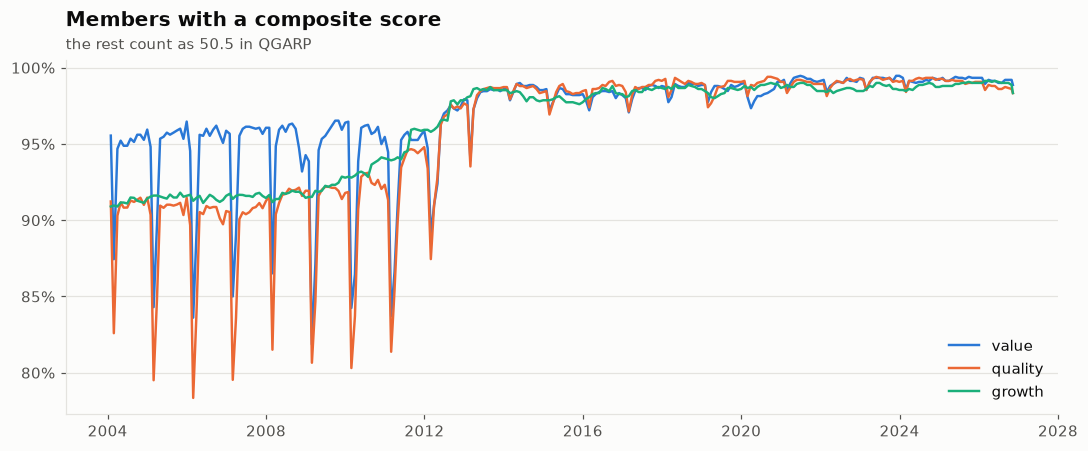

In [2]:
missing = pd.Series(bg.NOT_YET_BUILT).rename("needs").rename_axis("factor").reset_index()
display(
    pd.DataFrame(
        {"scores": [len(bg.BUILT), len(bg.NOT_YET_BUILT), len(bg.COMPOSITES)]},
        index=["factors built", "factors not yet built", "composites"],
    ).T
)
display(missing.groupby("needs").size().rename("factors").sort_values(ascending=False).to_frame())

cover = bg.coverage(result.factors, bg.BUILT)
print("Built factors with the lowest coverage:")
display(cover.sort_values("average").head(12).style.format("{:.0%}"))
display(bg.coverage(result.composites, bg.COMPOSITES).style.format("{:.0%}"))
over_time = bg.coverage_over_time(result.composites, bg.COMPOSITES[:-1])
fig = charts.lines(
    {
        "value": over_time["pct_rank_value_composite"],
        "quality": over_time["pct_rank_quality_composite"],
        "growth": over_time["pct_rank_growth_composite"],
    },
    "Members with a composite score",
    subtitle="the rest count as 50.5 in QGARP",
    percent=True,
)
display(over_time.groupby(over_time.index.year).mean().rename_axis("year").T.style.format("{:.0%}"))
display(
    result.factors["industry"].value_counts(normalize=True).rename("share of rows").to_frame().style.format("{:.0%}")
)

## Cleaning: what the limits remove

Before a factor is ranked, each value is checked against the factor's two limits; one outside them is set to
missing. The limits are a **rule set** in the database - a named collection of rules, loaded once and never changed
afterwards, so that a registered run can always say exactly which limits it used. The table counts, for the factors that lose most, the values each had before cleaning, how many lay below
the lower limit and above the upper one, and the share removed. A factor that loses a large share is either
measured differently here than in the original (our line items for Worldscope's) or has limits drawn tightly on
purpose - worth reading before trusting its ranks.

A removed value is not a removed company: the stock keeps its other factors, and a composite forms from those that
remain (QGARP counts a missing composite rank as 50.5, the middle).

In [3]:
removed = result.removed
if removed is None or removed.empty:
    print("No cleaning limits in this run (RULES is None): nothing is removed")
else:
    rules = bg.shared_rules(cache, config.rules)  # from research.strategy_rule, through the cache
    sets = strategy_rules.rule_sets(cache).set_index("code")
    display(sets.loc[[config.rules], ["strategy", "rules", "loaded_at", "source"]])
    total = removed[["values", "below", "above"]].sum()
    outside = total["below"] + total["above"]
    print(f"Rule set {config.rules}: limits for {len(rules)} scores, {len(removed)} of them factors built here")
    print(
        f"{outside / total['values']:.2%} of all factor values lie outside their limits "
        f"({int(total['below']):,} below, {int(total['above']):,} above, of {int(total['values']):,})"
    )
    print(
        f"{int((removed['removed'] == 0).sum())} factors lose nothing; "
        f"{int((removed['removed'] > 0.05).sum())} lose more than 5 % of their values"
    )
    limits = rules.set_index("barings_metric_name")[["lower_limit", "upper_limit"]]
    worst = removed.join(limits).sort_values("removed", ascending=False).head(15)
    display(
        worst[["lower_limit", "upper_limit", "values", "below", "above", "removed"]].style.format(
            {
                "lower_limit": "{:,.4g}",
                "upper_limit": "{:,.4g}",
                "values": "{:,.0f}",
                "below": "{:,.0f}",
                "above": "{:,.0f}",
                "removed": "{:.1%}",
            }
        )
    )
    without = sorted(set(bg.BUILT) - set(rules["barings_metric_name"]))
    print(f"{len(without)} factors built here have no limits and are kept whole:", ", ".join(without))

,strategy,rules,loaded_at,source
code,,,,
gems-2026-11,barings_qgarp,234,2026-11-16 21:22:58,Barings' limits of November 2026 (github.com/m...


Rule set gems-2026-11: limits for 117 scores, 100 of them factors built here
1.01% of all factor values lie outside their limits (115,450 below, 233,188 above, of 34,682,438)
6 factors lose nothing; 4 lose more than 5 % of their values


,lower_limit,upper_limit,values,below,above,removed
factor,,,,,,
sales_to_ev,0,1,"388,005","1,105","95,640",24.9%
operating_leverage,0,30,"339,832",0,"32,275",9.5%
payout_ratio,0,3,"398,519","21,717","6,376",7.0%
ebitda_to_ev,0,20,"312,596","18,516",28,5.9%
debt_to_equity,-5,5,"369,086","4,553","9,627",3.8%
eps_growth_1_year_hist,-1,10,"394,480","6,834","6,299",3.3%
eps_ntm_3mth_chg,-1,1,"376,686","4,144","5,130",2.5%
ebit_yield_3_year_hist,-0.5,0.5,"376,852","2,491","4,456",1.8%
ebit_yield_5_year_hist,-0.5,0.5,"335,380","1,605","4,307",1.8%


17 factors built here have no limits and are kept whole: accruals_year_on_year_change, capital_adequacy_ratio_tier_1_capital, capital_adequacy_ratio_total_capital, interest_income_to_interest_expense, loan_loss_provisions_to_net_loans, loans_to_deposits, market_capitalization, net_income_5_year_stability, net_income_margin_5_year_vol, net_income_to_risk_weighted_assets, net_interest_income_to_net_loan, non_interest_income_to_non_interest_expense, non_performing_loans_to_equity_and_loan_loss_provision, return_on_assets_5_year_vol, return_on_equity_5_year_vol, return_on_invested_capital_5_year_vol, sustainable_growth_3_year_average


### Do the limits change the result?

The same strategy run again without the limits (`rules=None`) - also registered, so the family's trial count and
its deflated Sharpe ratios include both. The table compares the two books; *names in common* is the share of the
with-limits book's holdings that the other book also holds, averaged over the rebalances.

In [4]:
from dataclasses import replace

if config.rules is None:
    print("This run has no limits: nothing to compare")
else:
    plain = bg.run_barings_garp(cache, replace(config, rules=None), engine=engine)
    shown = ["cagr", "vol", "sharpe", "max_drawdown", "active_return", "information_ratio", "turnover"]
    compare = pd.DataFrame(
        {
            f"with the limits (run {result.run_id})": {k: result.metrics.get(k) for k in shown},
            f"without (run {plain.run_id})": {k: plain.metrics.get(k) for k in shown},
        }
    ).T
    display(
        compare.style.format(
            {
                "cagr": "{:.1%}",
                "vol": "{:.1%}",
                "sharpe": "{:.2f}",
                "max_drawdown": "{:.0%}",
                "active_return": "{:+.1%}",
                "information_ratio": "{:+.2f}",
                "turnover": "{:.1f}",
            }
        )
    )
    held, other = result.book > 0, plain.book.reindex_like(result.book).fillna(0.0) > 0
    common = (held & other).sum(axis=1) / held.sum(axis=1)
    by_date = result.score.corrwith(plain.score, axis=1, method="spearman")  # across members, on each rebalance
    print(f"Names in common: {common.mean():.0%} on average ({common.min():.0%} to {common.max():.0%})")
    print(f"Rank correlation of the two QGARP scores across members: {by_date.mean():.3f} on average")
    print("Trials of this family now:", plain.metrics["trials"])

left out 1078 facts of 2 companies in ['GBP']
left out 1078 facts of 2 companies in ['GBP']


,cagr,vol,sharpe,max_drawdown,active_return,information_ratio,turnover
with the limits (run 165),11.0%,22.2%,0.58,-59%,+0.2%,+0.10,2.6
without (run 166),10.9%,22.3%,0.58,-60%,+0.2%,+0.10,2.6


Names in common: 98% on average (96% to 100%)
Rank correlation of the two QGARP scores across members: 0.995 on average
Trials of this family now: 10


### Revisions without survivorship bias

QGARP gives 10 % to earnings-estimate revisions: the *breadth* of analysts' revisions, (raised - lowered) /
estimates. In a **backtest** that input is biased: LSEG returns past revision counts only for companies still listed
today - a company since delisted or acquired answers 0 raised and 0 lowered - so only the survivors are scored on it.
(A **screen** of today's companies is not affected: they are all listed, and their counts are real.)

Two ways round it, each run and registered as a trial of the family:

* **No revisions** - the weight set to zero, the other four inputs in Barings' proportions.
* **Consensus revisions** - the same 10 % given to revisions measured from the consensus itself: how much the FY1
  and FY2 EPS consensus moved in the month, for the same fiscal year, over the price (Chan, Jegadeesh and
  Lakonishok, 1996). LSEG's consensus history covers the departed companies too, so this measure has no
  survivorship bias. It is ranked exactly as the original ranks its revisions, so the only change is where the
  revisions come from. It stands in for breadth in this backtest only - the screen keeps the analyst counts.

The first table shows each revisions input's coverage of the members by year: the counts thin out the further back
the year (fewer of those companies are still listed), the consensus revisions do not.

In [5]:
from dataclasses import replace

counts_cover = result.composites[bg.REVISIONS_1_MTH].notna().groupby(result.composites["date"].dt.year).mean()
consensus_cover = (
    result.composites[bg.CONSENSUS_REVISIONS_1_MTH].notna().groupby(result.composites["date"].dt.year).mean()
)
display(
    pd.DataFrame({"revision counts (breadth)": counts_cover, "consensus revisions": consensus_cover}).T.style.format(
        "{:.0%}"
    )
)

base = dict(config.qgarp_weights)
if bg.REVISIONS_1_MTH not in base:
    print("These weights give the revisions nothing: nothing to compare")
else:
    no_revisions = {name: w for name, w in base.items() if name != bg.REVISIONS_1_MTH}
    consensus = {**no_revisions, bg.CONSENSUS_REVISIONS_1_MTH: base[bg.REVISIONS_1_MTH]}
    variants = {
        f"revision counts (run {result.run_id})": result,
    }
    for label, weights in (("no revisions", no_revisions), ("consensus revisions", consensus)):
        run = bg.run_barings_garp(cache, replace(config, qgarp_weights=weights), engine=engine)
        variants[f"{label} (run {run.run_id})"] = run
    shown = ["cagr", "vol", "sharpe", "max_drawdown", "active_return", "information_ratio", "turnover"]
    display(
        pd.DataFrame({label: {k: r.metrics.get(k) for k in shown} for label, r in variants.items()}).T.style.format(
            {
                "cagr": "{:.1%}",
                "vol": "{:.1%}",
                "sharpe": "{:.2f}",
                "max_drawdown": "{:.0%}",
                "active_return": "{:+.1%}",
                "information_ratio": "{:+.2f}",
                "turnover": "{:.1f}",
            }
        )
    )
    held = result.book > 0
    for label, run in list(variants.items())[1:]:
        other = run.book.reindex_like(result.book).fillna(0.0) > 0
        common = (held & other).sum(axis=1) / held.sum(axis=1)
        corr = result.score.corrwith(run.score, axis=1, method="spearman")
        print(
            f"{label}: {common.mean():.0%} of names in common with the revision counts' book on average, "
            f"score rank correlation {corr.mean():.3f}"
        )
    print("Trials of this family now:", list(variants.values())[-1].metrics["trials"])

date,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
revision counts (breadth),41%,42%,45%,48%,51%,54%,56%,59%,61%,62%,64%,67%,70%,72%,74%,77%,80%,82%,85%,87%,90%,93%,88%
consensus revisions,86%,87%,87%,88%,88%,89%,91%,92%,93%,92%,92%,93%,94%,94%,94%,94%,95%,95%,95%,95%,95%,96%,88%


left out 1078 facts of 2 companies in ['GBP']
left out 1078 facts of 2 companies in ['GBP']
left out 1078 facts of 2 companies in ['GBP']
left out 1078 facts of 2 companies in ['GBP']


,cagr,vol,sharpe,max_drawdown,active_return,information_ratio,turnover
revision counts (run 165),11.0%,22.2%,0.58,-59%,+0.2%,+0.10,2.6
no revisions (run 167),10.4%,22.3%,0.56,-59%,-0.3%,+0.05,2.7
consensus revisions (run 168),10.6%,22.0%,0.57,-58%,-0.1%,+0.06,3.3


no revisions (run 167): 91% of names in common with the revision counts' book on average, score rank correlation 0.987
consensus revisions (run 168): 88% of names in common with the revision counts' book on average, score rank correlation 0.971
Trials of this family now: 12


## Performance

The portfolio against SPTM over the same dates, with the active statistics (see notebook 3.1): the information ratio
and the deflated active Sharpe ratio show whether stock selection added anything beyond market exposure.

,cagr,vol,sharpe,max_drawdown
QGARP book,11.0%,22.2%,0.58,-59%
benchmark,10.7%,19.1%,0.63,-55%


,beta,alpha,active_return,tracking_error,information_ratio,deflated_active_sharpe,turnover
QGARP against the benchmark,1.13,-0.7%,+0.2%,8.3%,+0.10,15%,2.6


,QGARP book,benchmark,difference
trade_date,,,
2004,+19.0%,+8.8%,+10.2%
2005,+9.2%,+6.7%,+2.5%
2006,+17.7%,+14.8%,+2.9%
2007,-4.0%,+5.2%,-9.2%
2008,-34.3%,-36.7%,+2.4%
2009,+39.1%,+28.0%,+11.1%
2010,+26.2%,+17.3%,+8.9%
2011,+1.7%,+0.8%,+0.9%
2012,+21.5%,+15.9%,+5.6%


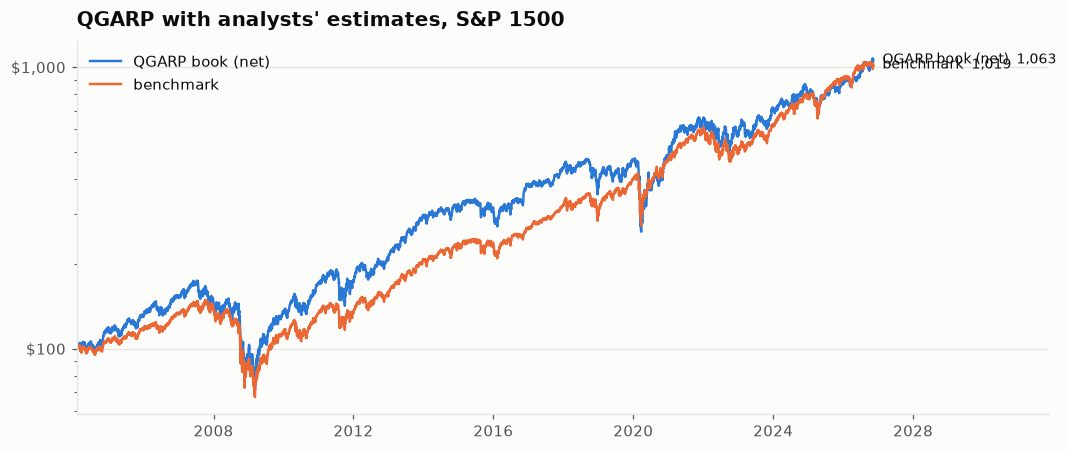

In [6]:
table = pd.DataFrame({"QGARP book": performance(net), "benchmark": performance(bench)}).T
display(table.style.format({"cagr": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}"}))
m = result.metrics
ACTIVE = {
    "beta": "{:.2f}",
    "alpha": "{:+.1%}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "deflated_active_sharpe": "{:.0%}",
    "turnover": "{:.1f}",
}
display(pd.DataFrame({"QGARP against the benchmark": {k: m.get(k) for k in ACTIVE}}).T.style.format(ACTIVE))
fig = charts.growth({"QGARP book (net)": net, "benchmark": bench}, "QGARP with analysts' estimates, S&P 1500")
years = calendar_years({"QGARP book": net, "benchmark": bench})
years["difference"] = years["QGARP book"] - years["benchmark"]
display(years.style.format("{:+.1%}"))

### In sample and hold-out

The same book measured separately over the years the research could see (to the end of 2024) and over the hold-out
(from January 2025): its return, the benchmark's, and the active statistics of each period. `active_t` is the
t-statistic of the mean monthly active return - with few months, a large active return can still be noise.

In [7]:
from research_core.analytics.performance.metrics import periods_against

HOLDOUT = "2025-01-01"  # the research hold-out's first day (settings.holdout_start)
split = periods_against(net, bench, HOLDOUT)
display(split.style.format({"months": "{:.0f}", "cagr": "{:.1%}", "vol": "{:.1%}", "max_drawdown": "{:.0%}",
          "benchmark_cagr": "{:.1%}",
          "beta": "{:.2f}", "alpha": "{:+.1%}", "active_return": "{:+.1%}", "tracking_error": "{:.1%}",
          "information_ratio": "{:+.2f}", "active_t": "{:+.2f}"}))  # fmt: skip

,months,cagr,vol,max_drawdown,benchmark_cagr,beta,alpha,active_return,tracking_error,information_ratio,active_t
before 2025-01-01,251,10.5%,22.6%,-59%,10.3%,1.16,-1.0%,+0.2%,7.8%,+0.11,+0.50
from 2025-01-01,23,16.5%,17.8%,-20%,16.0%,0.57,+7.1%,+0.4%,12.6%,+0.05,+0.06


## Decile analysis of the composites

Each month the constituents are sorted into deciles by a score, and each decile's return to the next month end is
compared with the universe average (equal-weighted, before costs, annualised; `t` is its t-statistic). A score with
predictive power shows returns rising monotonically from the first decile (worst) to the tenth (best). The deciles are
only this diagnostic: the scores themselves use the strategy's percentile ranks.

In [8]:
composite = {
    "QGARP": "pct_rank_qgarp",
    "value": "pct_rank_value_composite",
    "growth": "pct_rank_growth_composite",
    "quality alpha": "pct_rank_quality_alpha",
    "quality defensive": "pct_rank_quality_defensive",
    "momentum": "zscore_momentum_composite",
    "revisions (4 months)": "zscore_earnings_revisions_4_mth_composite",
    "consensus revisions (1 month)": bg.CONSENSUS_REVISIONS_1_MTH,
}
scores = {label: bg.score_panel(result.composites, name) for label, name in composite.items()}
deciles = pd.concat(
    {name: decile_returns(s, result.returns, result.members)["excess"] for name, s in scores.items()}, axis=1
)
display(deciles.style.format("{:+.1%}"))
spread = pd.DataFrame(
    {
        name: decile_returns(s, result.returns, result.members)
        .loc[[1, 10]]
        .assign(what=["worst tenth", "best tenth"])
        .set_index("what")["t"]
        for name, s in scores.items()
    }
)
display(spread.style.format("{:+.1f}"))

,QGARP,value,growth,quality alpha,quality defensive,momentum,revisions (4 months),consensus revisions (1 month)
decile,,,,,,,,
1,-1.9%,-2.2%,+0.8%,-1.1%,-0.1%,+0.2%,+1.6%,-0.9%
2,-0.4%,-1.6%,-0.4%,-1.1%,+0.2%,+0.6%,-2.2%,-1.0%
3,-0.4%,-1.0%,+1.4%,+0.2%,+0.4%,+0.3%,-1.3%,+0.3%
4,-0.7%,-1.2%,+0.4%,+0.3%,+0.6%,+0.4%,-0.9%,-1.3%
5,-0.7%,-0.5%,-0.5%,-0.2%,+0.2%,+0.4%,-2.5%,-1.5%
6,+0.5%,+0.2%,+0.3%,-0.3%,-0.8%,-0.5%,-1.2%,-0.6%
7,+0.1%,+0.8%,-1.8%,+0.0%,-0.4%,-0.8%,-1.3%,-0.4%
8,+0.2%,+1.2%,+0.2%,+0.3%,+0.7%,-0.1%,-0.3%,+1.3%
9,+1.2%,+1.9%,-0.1%,+1.2%,+0.2%,-0.1%,+1.8%,+1.1%


,QGARP,value,growth,quality alpha,quality defensive,momentum,revisions (4 months),consensus revisions (1 month)
what,,,,,,,,
worst tenth,-1.4,-1.1,+0.5,-0.9,-0.0,+0.0,+1.7,-0.3
best tenth,+1.9,+1.2,-0.2,+0.5,-0.9,-0.1,+6.7,+2.6


## Which factors predict on their own

The same triage as notebook 5.2's step 2, on QGARP's ingredients: each factor built here, each composite and the
consensus revisions, tested **alone** against the next month's return. Each month end the rank correlation (the
**IC**) between the factor and the members' next-month returns; its average over 2010-2026 (hold-out included) with a Newey-West
t-statistic (no lags: monthly returns do not overlap), the two-sided p-value, and the Benjamini-Hochberg verdict at a
false-discovery rate of 10 % across *all* the factors tested. With over a hundred factors, about one in twenty would
pass a single test at 5 % by chance alone; the false-discovery control raises the bar to keep flukes rare.

How to read the sign: a factor keeps its own sign - a positive IC means a higher value went with a higher return
(earnings yield), a negative one that a higher value went with a lower return (debt, volatility). A composite is
turned so that higher is better, so a positive IC means it ranked the right way round. The cleaned factors are used,
as QGARP uses them. `spread` is the best fifth's next-month return less the worst fifth's, `turnover` the share of the
top fifth replaced each month, and `rank_autocorrelation` how much the ranking persists from one month to the next.

`calculation` says what kind of number each score is - a ratio, a growth rate, a standard deviation, a regression
t-statistic, a z-score, a percentile rank and so on - read from its formula; the table under the ranking explains each
kind. It helps to read the table: scores of one kind tend to behave alike (the five-year standard deviations, for
example, all measure stability, negated so that a steadier company scores higher).

126 tested (of 127: the rest have no data); 26 are discoveries at a 10% false-discovery rate: 20 factors, 6 composites


,kind,calculation,mean_ic,t_nw,p_value,discovery,spread,turnover,rank_autocorrelation
signal,,,,,,,,,
zscore_earnings_revisions_4_mth_composite,composite,z-score,+0.0171,+5.36,0.0000,True,+0.41%,3%,1.00
earnings_revisions_4_mth,factor,revision breadth,+0.0171,+5.30,0.0000,True,+0.41%,3%,1.00
earnings_revisions_1_mth,factor,revision breadth,+0.0165,+5.16,0.0000,True,+0.39%,5%,1.00
earnings_revision_persistence_6mth,factor,count of signs,+0.0120,+4.13,0.0000,True,+nan%,nan%,1.00
pct_rank_qgarp,composite,percentile rank,+0.0205,+4.06,0.0000,True,+0.23%,14%,0.94
sustainable_growth_3_year_average,factor,average of ratios,+0.0183,+3.48,0.0005,True,+0.15%,5%,0.97
loans_to_deposits,factor,ratio,+0.0369,+3.20,0.0014,True,+0.49%,5%,0.99
earnings_yield_ntm,factor,ratio,+0.0234,+3.15,0.0016,True,+0.31%,11%,0.97
earnings_yield,factor,ratio,+0.0167,+3.05,0.0023,True,+0.16%,12%,0.95


,scores tested,discoveries,what it is
calculation,,,
ratio,59,13,one figure divided by another on the date (a y...
growth rate,12,0,a figure's change over a year (or from last ye...
compound growth rate,7,0,the yearly growth rate that compounds to the c...
change in a ratio,8,0,a ratio now less the same ratio a year (or thr...
average of ratios,1,1,the mean of a ratio over the last three years
product of ratios,2,2,return on equity times the share of profits ke...
ratio of growth rates,1,0,profit growth divided by sales growth
standard deviation,6,0,how much a series varied: of yearly ratios ove...
coefficient of variation,2,1,a standard deviation divided by the size of th...


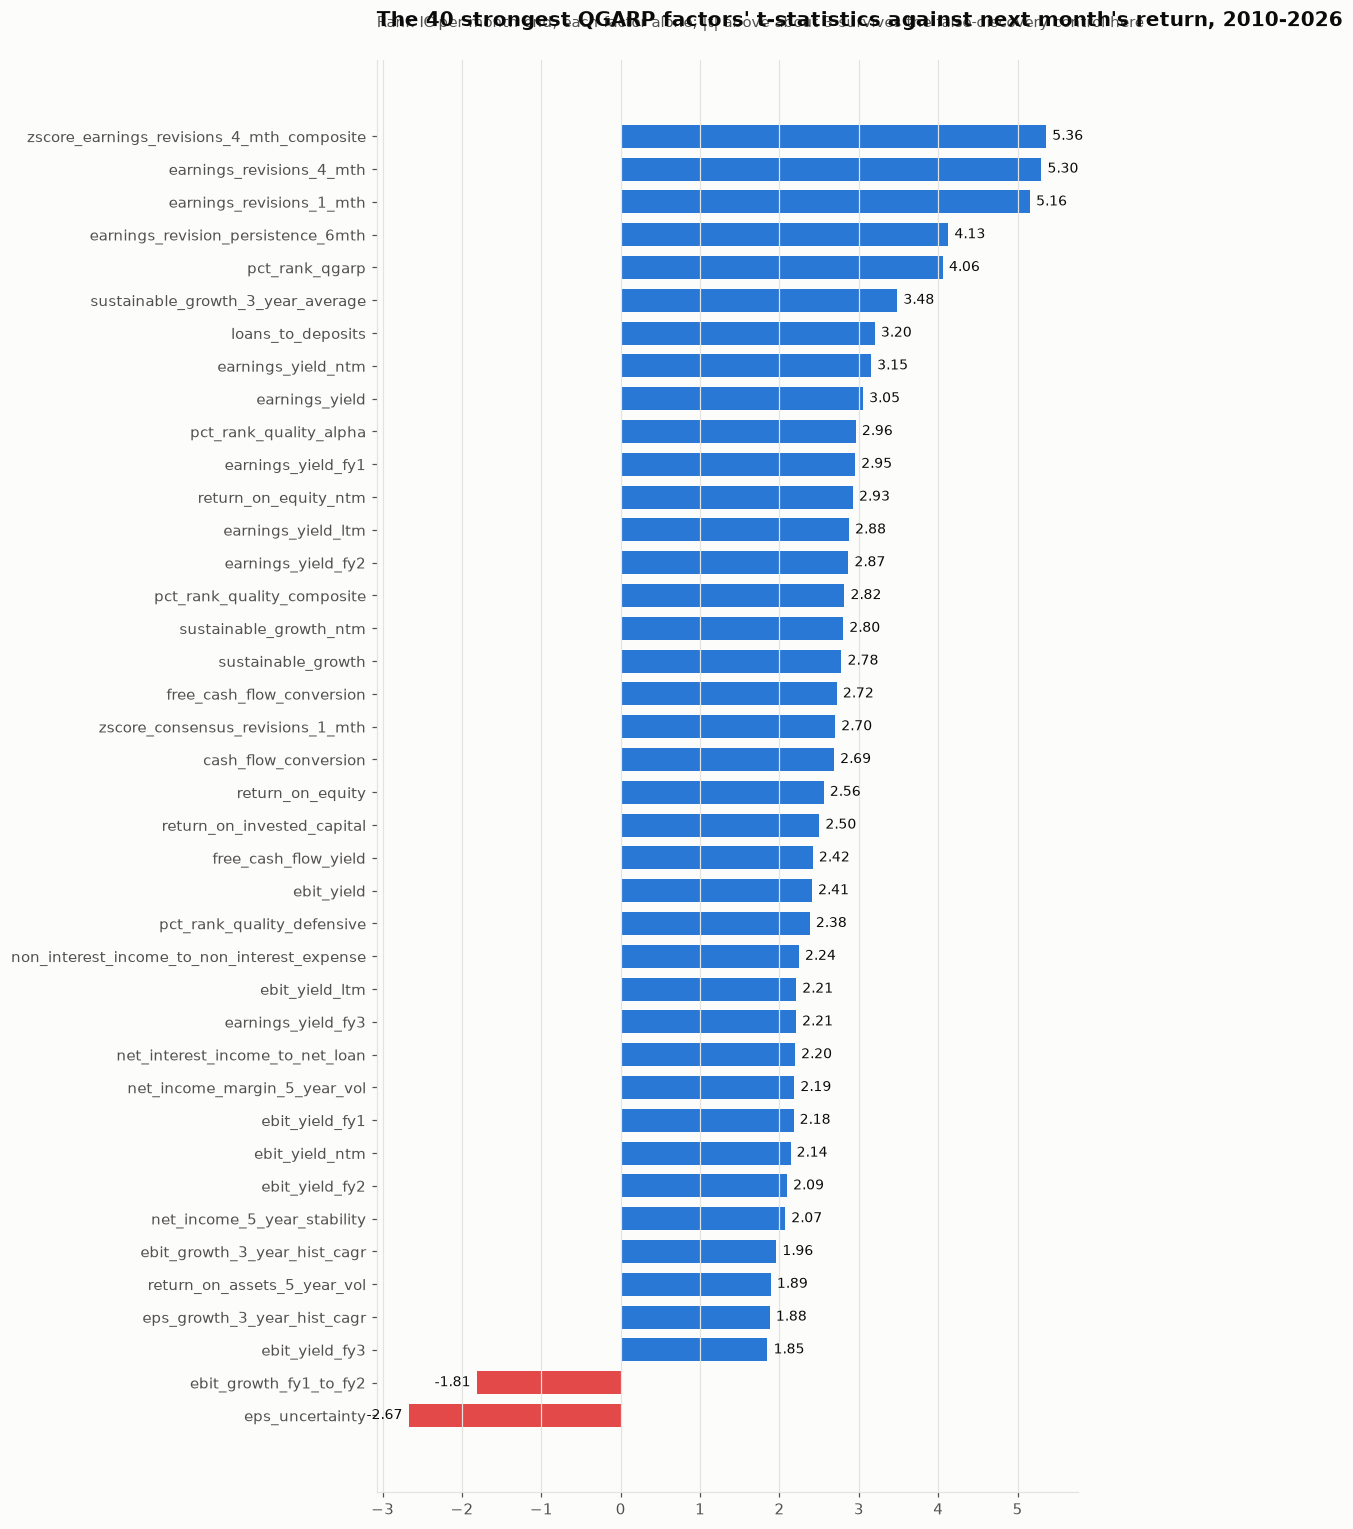

In [9]:
from research_core.analytics.signals import evaluation as ev
from research_core.analytics.signals import labels as lb

FDR = 0.10
tested = [*bg.BUILT, *bg.COMPOSITES, bg.CONSENSUS_REVISIONS_1_MTH]
panels = bg.factor_panels(result.factors, bg.BUILT) | bg.factor_panels(
    result.composites, [*bg.COMPOSITES, bg.CONSENSUS_REVISIONS_1_MTH]
)
next_month = lb.period_returns(result.returns, result.book.index)  # each month end's return to the next
ledger = ev.triage(panels, next_month, result.members, lags=0, q=FDR)
ledger.insert(0, "kind", ["composite" if n in (*bg.COMPOSITES, bg.CONSENSUS_REVISIONS_1_MTH) else "factor"
                          for n in ledger.index])  # fmt: skip
ledger.insert(1, "calculation", ledger.index.map(bg.calculation))
found = ledger[ledger["discovery"]]
print(
    f"{len(panels)} tested (of {len(tested)}: the rest have no data); {len(found)} are discoveries at a "
    f"{FDR:.0%} false-discovery rate: {len(found[found['kind'] == 'factor'])} factors, "
    f"{len(found[found['kind'] == 'composite'])} composites"
)
STYLE = {"mean_ic": "{:+.4f}", "t_nw": "{:+.2f}", "p_value": "{:.4f}", "spread": "{:+.2%}", "turnover": "{:.0%}",
         "rank_autocorrelation": "{:.2f}"}  # fmt: skip
display(ledger.style.format(STYLE))  # every factor tested, strongest first
kinds = pd.Series(bg.CALCULATION_KINDS, name="what it is").rename_axis("calculation").to_frame()
kinds.insert(0, "scores tested", ledger["calculation"].value_counts().reindex(kinds.index).fillna(0).astype(int))
kinds.insert(1, "discoveries", found["calculation"].value_counts().reindex(kinds.index).fillna(0).astype(int))
display(kinds[kinds["scores tested"] > 0])
fig = charts.ranked_bars(
    ledger["t_nw"].head(40),
    "The 40 strongest QGARP factors' t-statistics against next month's return, 2010-2026",
    subtitle="Rank IC per month end, each factor alone; |t| above about 3 survives the false-discovery control here",
)

In [10]:
# the composites and the inputs QGARP weighs, side by side
display(ledger[ledger["kind"] == "composite"].style.format(STYLE))
print(
    f"Factors with |t| >= 2 that are not discoveries: {len(ledger[(ledger['t_nw'].abs() >= 2) & ~ledger['discovery']])}"
)

,kind,calculation,mean_ic,t_nw,p_value,discovery,spread,turnover,rank_autocorrelation
signal,,,,,,,,,
zscore_earnings_revisions_4_mth_composite,composite,z-score,+0.0171,+5.36,0.0000,True,+0.41%,3%,1.00
pct_rank_qgarp,composite,percentile rank,+0.0205,+4.06,0.0000,True,+0.23%,14%,0.94
pct_rank_quality_alpha,composite,percentile rank,+0.0147,+2.96,0.0031,True,+0.17%,9%,0.96
pct_rank_quality_composite,composite,percentile rank,+0.0176,+2.82,0.0048,True,+0.07%,12%,0.96
zscore_consensus_revisions_1_mth,composite,z-score,+0.0149,+2.70,0.0069,True,+0.29%,70%,0.25
pct_rank_quality_defensive,composite,percentile rank,+0.0141,+2.38,0.0173,True,-0.04%,15%,0.95
pct_rank_value_composite_fins_neutral,composite,percentile rank,+0.0129,+1.52,0.1281,False,+0.35%,12%,0.97
pct_rank_value_composite,composite,percentile rank,+0.0130,+1.49,0.1363,False,+0.34%,12%,0.98
pct_rank_growth_composite,composite,percentile rank,+0.0065,+1.19,0.2337,False,-0.03%,15%,0.92


Factors with |t| >= 2 that are not discoveries: 9


## Current holdings

The stocks held after the last rebalance, with their composite percentile ranks (1 = best).

In [11]:
last = result.book.index.max()
held = result.book.loc[last]
held = held[held > 0].index
latest = result.composites[result.composites["date"] == result.composites["date"].max()].set_index("listing_id")
names = cache.query(
    "SELECT listing_id, name FROM core.listing WHERE listing_id IN (" + ", ".join(str(int(i)) for i in held) + ")"
).set_index("listing_id")["name"]
book = latest.reindex(held)[
    ["pct_rank_qgarp", "pct_rank_quality_alpha", "pct_rank_quality_defensive", "pct_rank_value_composite"]
]
book.insert(0, "name", names.reindex(book.index))
print(f"{len(held)} names held after {last:%d %b %Y}")
display(book.sort_values("pct_rank_qgarp").head(25))

378 names held after 11 Nov 2026


,name,pct_rank_qgarp,pct_rank_quality_alpha,pct_rank_quality_defensive,pct_rank_value_composite
listing_id,,,,,
201,Century Aluminum Company,1,32,59,4
233,Hci Group Inc,1,11,49,15
3097,"The Gap, Inc.",1,34,41,3
261,Marathon Petroleum Corporation,1,3,48,6
2800,Occidental Petroleum Corp,1,23,52,4
1229,Valero Energy Corp,1,2,49,8
1027,Teradata Corporation,1,1,43,15
2731,"First Interstate BancSystem, Inc.",1,26,11,7
2369,HF Sinclair Corporation,1,28,33,2


## Findings

*Rerun on 14 November 2026 on the rebuilt database (`equity_research_local`, data to 12 November 2026), returns
counting spin-offs and the missing splits now loaded, with
Barings' QGARP weights (0.2 alpha, 0.1 defensive, 0.3 growth, 0.3 value, 0.1 revisions), Barings' cleaning
limits (rule set `gems-2026-11`) and one correction to the original: the revisions input ranked the right way round
(`FIX_REVISIONS_DIRECTION = True`, decided before this run). QGARP is used as a screen of today's companies; this
backtest asks how such a screen would have done historically.*

* **Closer to SPTM, still behind.** From 2010 to 2024 the portfolio of the screen's best names returned 12.9 % a
  year against SPTM's 14.0 %, with higher volatility (21.1 % against 17.2 %), a deeper maximum drawdown (-45 % against
  -35 %) and a beta of 1.19: an active return of -1.0 % a year and an information ratio of -0.03. After the family's
  eighteen trials in this database's registry (notebook 3.5's S&P 500 runs belong to it too), the probability that
  the active bet reflects skill is 2 %.
* **Correcting the revisions direction is worth about 0.9 points a year.** As originally coded, the revisions
  z-score is ranked so that the *worst* revisions score best; that version (run 16, from before the spin-off fix to returns,
  which adds about 0.1 point) returned 12.0 % a year (information ratio -0.12). Ranked the right way round, the same 10 % weight lifts the result to 12.9 % (-0.03). Without
  revisions at all it is 12.3 % (-0.09); with the survivorship-free consensus revisions, corrected, 12.5 % (-0.08) -
  so the gain is not only the survivor bias in the analyst counts.
* **The same years as before.** Ahead when value stocks led - 2010 (+7.6 points), 2012 (+5.6), 2013 (+8.9), 2016
  (+9.0), 2021 (+4.6), 2022 (+5.7); behind when mega-cap growth led - 2017 (-5.9), 2018 (-7.7), 2019 (-6.7), 2020
  (-14.3), 2024 (-11.1). An equally weighted book of ~370 stocks is also smaller on average than SPTM, and part of the
  gap is that size tilt.
* **The cleaning limits barely change the result.** 0.98 % of all factor values lie outside their limits (232,002 of
  23.6 million) and are set to missing. Without the limits the strategy returns 12.8 % a year; the two books share
  98 % of their names, and the two scores rank the members almost identically (rank correlation 0.996).
* **One limit removes far more than the rest: `sales_to_ev`.** Its limits of 0 to 1 remove 23.4 % of its values -
  every company whose sales exceed its enterprise value, which low-margin businesses (retailers, distributors)
  routinely do. `operating_leverage` (9.6 %), `payout_ratio` (7.4 %: negative payouts) and `ebitda_to_ev` (5.6 %:
  negative EBITDA) come next; every other factor loses under 5 %.
* **Revision counts thin out going back; the consensus revisions do not.** The counts score 56 % of members in 2010
  and 90 % in 2024 - LSEG has past counts only for companies still listed today. The consensus revisions, measured
  from the consensus history, score 91-96 % throughout.

**Which factors predict on their own (the triage).** Of 126 factors and composites tested alone against the next
month's return, 14 are discoveries at a 10 % false-discovery rate - 9 factors and 5 composites - and 9 more have
|t| of 2 or more without surviving the control.

* **QGARP itself ranks next month's returns** (IC +0.0195, t +3.01), but mostly through **quality**: the quality
  composite (t +2.95), its alpha half (+2.94) and defensive half (+2.60) are discoveries, as are sustainable growth
  (3-year average t +3.50, forward +2.55), forward return on equity (+2.57) and free-cash-flow conversion (+2.92).
  Analysts' disagreement predicts the other way: higher EPS forecast dispersion, lower returns (t -2.67).
* **Value, growth and momentum do not, on their own.** The value composite has t +0.49, growth +1.37, momentum +0.04 -
  yet value and growth carry 60 % of QGARP's weight. That is an observation, not a reason to reweight: changing the
  weights after seeing this table would be fitting it, and any reweighting is a new trial to be chosen in advance.
* **The revision counts top the table - read them with care.** The 4-month revisions composite (t +4.04), the 4- and
  1-month breadth (+3.90, +3.74) and revision persistence (+3.16) are the strongest, but they are measured only on
  the survivors. The survivorship-free consensus revisions point the same way more weakly (t +1.99, not a
  discovery). Revisions do predict; how strongly, the counts overstate.
* **One bank ratio is a discovery on few companies**: loans to deposits (t +3.02) covers only the ~6 % of members
  that are banks - a small sample, not a general signal.
* **The ranking works on average but not where the book is.** QGARP's ranking has an IC of +0.0195 across all
  members, yet its best tenth beat the universe by only 1.2 % a year (t 1.0) and its worst lagged by 2.3 % (t -1.4):
  the information sits more at the bottom - which a long-only book cannot use - than at the top it buys.

## Next steps

1. **The revisions direction** - the screen now ranks revisions the right way round; as originally coded, the input
   rewards analyst downgrades. `FIX_REVISIONS_DIRECTION = False` reproduces the original exactly.
2. **`sales_to_ev`'s limit** - an upper limit of 1 removes every company whose sales exceed its enterprise value: is
   that deliberate, or is the original's sales / EV on another basis? A few retailers and distributors would show it.
3. **The other rule types** - besides the limits, the original's rules exclude financials from some factors, invert
   some and take logs of others; only the limits are carried over. The rule tables can already hold
   `exclude_financials` (which the cleaning applies) and `invert` rules.

## Glossary

* **Percentile rank** - a stock's position among the day's constituents in percent: 1 is the best, 100 the worst.
* **Composite** - an average of several factors' percentile ranks, ranked again.
* **Buffer** - a holding is kept while it stays in the top 30 %, though new purchases need the top 20 %.
* **Cleaning limits** - the range a factor's values must lie in; a value outside it is set to missing (not moved to
  the limit), so the company is not ranked on that factor.
* **Rule set** - a named collection of rules (here the cleaning limits) kept in the shared tables and never changed
  once loaded, so a registered run can always say which rules it used.
* **Revision breadth** - (analysts raising their forecast - analysts lowering it) / analysts; **consensus revision** -
  how much the average forecast itself moved, over the share price.
* **IC (information coefficient)** - each month, the rank correlation between a factor and the members' next-month
  returns; **Benjamini-Hochberg** - the control that keeps the expected share of chance results among the
  discoveries at 10 %.
* **Survivorship bias** - a sample restricted to companies that survived to today, which overstates past returns.
* **Active return**, **information ratio**, **deflated Sharpe ratio** - see notebook 3.1.